##  Applying Matrix-Based Approach  to the PDE

The governing equation for the problem is

$$
u_t = c_d u_{xx} + F(u),
$$

where

$$
F(u)=c_su(1-u)(u-a).
$$

After applying the Chebyshev spectral approximation in space,

$$
u_{xx}\approx D^{(2)}U,
$$

where

$$
D^{(2)}=D^2,
$$

the PDE becomes

$$
\frac{dU}{dt}
=
c_dD^{(2)}U+F(U).
$$

We let the entire right-hand side as one function:

$$
G(U)
=
c_dD^{(2)}U+F(U).
$$

Therefore,

$$
\frac{dU}{dt}=G(U).
$$

The Crank--Nicolson method approximates the time derivative between two
consecutive time levels $t_n$ and $t_{n+1}$ by

$$
\frac{dU}{dt}
\approx
\frac{U^{n+1}-U^n}{\Delta t}.
$$

Crank--Nicolson then approximates the right-hand side of the equation
by averaging its value at the old time level $t_n$ and the new time
level $t_{n+1}$.

Therefore,

$$
G(U)
\approx
\frac{1}{2}
\left[
G(U^{n+1})+G(U^n)
\right].
$$

Hence,

$$
\boxed{
\frac{U^{n+1}-U^n}{\Delta t}
=
\frac{1}{2}
\left[
G(U^{n+1})+G(U^n)
\right]
}
$$

This is the main idea behind the Crank--Nicolson method.

In simple terms,

$$
\boxed{
\text{Crank--Nicolson uses the average of the PDE at }
t_n
\text{ and }
t_{n+1}.
}
$$

For the present problem,

$$
G(U)
=
c_dD^{(2)}U+F(U).
$$

At the new time level,

$$
G(U^{n+1})
=
c_dD^{(2)}U^{n+1}
+
F(U^{n+1}),
$$

while at the old time level,

$$
G(U^n)
=
c_dD^{(2)}U^n
+
F(U^n).
$$

Substituting these expressions into the Crank--Nicolson formula gives

$$
\frac{U^{n+1}-U^n}{\Delta t}
=
\frac{1}{2}
\left[
c_dD^{(2)}U^{n+1}
+
F(U^{n+1})
+
c_dD^{(2)}U^n
+
F(U^n)
\right].
$$

The diffusion terms can be grouped together:

$$
\boxed{
\frac{U^{n+1}-U^n}{\Delta t}
=
\frac{c_d}{2}D^{(2)}
\left(
U^{n+1}+U^n
\right)
+
\frac{1}{2}
\left[
F(U^{n+1})+F(U^n)
\right].
}
$$

This is the Crank--Nicolson discretization of the nonlinear PDE.

##  Identifying the Known and Unknown Quantities

At time level $t_n$, the solution

$$
U^n
$$

has already been calculated.

Therefore,

$$
\boxed{U^n \text{ is known}.}
$$

The purpose of the next time step is to calculate

$$
U^{n+1}.
$$

Therefore,

$$
\boxed{U^{n+1} \text{ is unknown}.}
$$

The Crank--Nicolson equation is

$$
\frac{U^{n+1}-U^n}{\Delta t}
=
\frac{c_d}{2}D^{(2)}
\left(
U^{n+1}+U^n
\right)
+
\frac{1}{2}
\left[
F(U^{n+1})+F(U^n)
\right].
$$

The quantities involving $U^n$ are known:

$$
U^n,
$$

$$
D^{(2)}U^n,
$$

and

$$
F(U^n).
$$

However, the quantities involving the new solution are unknown:

$$
U^{n+1},
$$

$$
D^{(2)}U^{n+1},
$$

and

$$
F(U^{n+1}).
$$

The main difficulty is the term

$$
F(U^{n+1}),
$$

because

$$
F(U)=c_sU(1-U)(U-a)
$$

is nonlinear.

Therefore, the Crank--Nicolson equation is not yet a linear system that
can be solved directly.

This is the point at which quasilinearization is required.


## Applying Quasilinearization to the New-Time Nonlinear Term

The nonlinear term at the new time level is

$$
F(U^{n+1}).
$$

Because $U^{n+1}$ is unknown, this term is also unknown and nonlinear.

To deal with this, an iterative approximation is introduced.

Let

$$
U_r^{n+1}
$$

denote the current approximation to the solution at the new time level.

The next approximation is denoted by

$$
U_{r+1}^{n+1}.
$$

Here,

$$
n
$$

represents the time step, while

$$
r
$$

represents the quasilinearization iteration inside that time step.

Using a first-order Taylor expansion about the current iterate
$U_r^{n+1}$ gives

$$
F\left(U_{r+1}^{n+1}\right)
\approx
F\left(U_r^{n+1}\right)
+
F'\left(U_r^{n+1}\right)
\left(
U_{r+1}^{n+1}
-
U_r^{n+1}
\right).
$$

Expanding the right-hand side gives

$$
F\left(U_{r+1}^{n+1}\right)
\approx
F'\left(U_r^{n+1}\right)
U_{r+1}^{n+1}
+
F\left(U_r^{n+1}\right)
-
F'\left(U_r^{n+1}\right)
U_r^{n+1}.
$$

Define

$$
A_r
=
F'\left(U_r^{n+1}\right),
$$

and

$$
B_r
=
F\left(U_r^{n+1}\right)
-
F'\left(U_r^{n+1}\right)
U_r^{n+1}.
$$

Therefore,

$$
\boxed{
F\left(U_{r+1}^{n+1}\right)
\approx
A_rU_{r+1}^{n+1}
+
B_r.
}
$$

Since $U$ is a vector containing the solution at all Chebyshev
collocation points, $A_r$ is also a vector.

To multiply each component of $U_{r+1}^{n+1}$ by the corresponding
component of $A_r$, the vector $A_r$ is placed on the diagonal of a
matrix.

Hence, in matrix form,

$$
\boxed{
F\left(U_{r+1}^{n+1}\right)
\approx
\operatorname{diag}(A_r)
U_{r+1}^{n+1}
+
B_r.
}
$$

The important point is that the nonlinear expression has now been
replaced by an expression that is linear in the new unknown
$U_{r+1}^{n+1}$.

##  Substituting the Quasilinearized Term into Crank--Nicolson

The Crank--Nicolson equation is

$$
\frac{U^{n+1}-U^n}{\Delta t}
=
\frac{c_d}{2}D^{(2)}
\left(
U^{n+1}+U^n
\right)
+
\frac{1}{2}
\left[
F(U^{n+1})+F(U^n)
\right].
$$

During quasilinearization, the new-time solution is written as

$$
U_{r+1}^{n+1}.
$$

Therefore,

$$
\frac{
U_{r+1}^{n+1}-U^n
}{\Delta t}
=
\frac{c_d}{2}D^{(2)}
\left(
U_{r+1}^{n+1}+U^n
\right)
+
\frac{1}{2}
\left[
F\left(U_{r+1}^{n+1}\right)
+
F(U^n)
\right].
$$

Using the quasilinearized approximation

$$
F\left(U_{r+1}^{n+1}\right)
\approx
\operatorname{diag}(A_r)
U_{r+1}^{n+1}
+
B_r,
$$

we obtain

$$
\frac{
U_{r+1}^{n+1}-U^n
}{\Delta t}
=
\frac{c_d}{2}D^{(2)}
\left(
U_{r+1}^{n+1}+U^n
\right)
+
\frac{1}{2}
\left[
\operatorname{diag}(A_r)
U_{r+1}^{n+1}
+
B_r
+
F(U^n)
\right].
$$

Expanding the diffusion term gives

$$
\frac{
U_{r+1}^{n+1}-U^n
}{\Delta t}
=
\frac{c_d}{2}
D^{(2)}U_{r+1}^{n+1}
+
\frac{c_d}{2}
D^{(2)}U^n
+
\frac{1}{2}
\operatorname{diag}(A_r)
U_{r+1}^{n+1}
+
\frac{1}{2}B_r
+
\frac{1}{2}F(U^n).
$$

At this stage the equation contains only linear terms involving the
new unknown

$$
U_{r+1}^{n+1}.
$$



## Multiplying the Equation by $\Delta t$


Multiply every term by $\Delta t$:

$$
U_{r+1}^{n+1}-U^n
=
\frac{c_d\Delta t}{2}
D^{(2)}U_{r+1}^{n+1}
+
\frac{c_d\Delta t}{2}
D^{(2)}U^n

+
\frac{\Delta t}{2}
\operatorname{diag}(A_r)
U_{r+1}^{n+1}
+
\frac{\Delta t}{2}B_r
+
\frac{\Delta t}{2}F(U^n).
$$

The purpose of this step is simply to remove the denominator
$\Delta t$ so that the equation can be rearranged more easily.

Now we identify the terms containing the unknown
$U_{r+1}^{n+1}$.

These are

$$
U_{r+1}^{n+1},
$$

$$
\frac{c_d\Delta t}{2}
D^{(2)}U_{r+1}^{n+1},
$$

and

$$
\frac{\Delta t}{2}
\operatorname{diag}(A_r)
U_{r+1}^{n+1}.
$$

Everything involving $U^n$ is already known from the previous time
step.

Also, $A_r$ and $B_r$ are treated as known during the current
quasilinearization iteration because they are calculated using the
previous iterate $U_r^{n+1}$.

## Moving the Unknown Terms to the Left-Hand Side

Starting from

$$
U_{r+1}^{n+1}-U^n
=
\frac{c_d\Delta t}{2}
D^{(2)}U_{r+1}^{n+1}
+
\frac{c_d\Delta t}{2}
D^{(2)}U^n
+
\frac{\Delta t}{2}
\operatorname{diag}(A_r)
U_{r+1}^{n+1}
+
\frac{\Delta t}{2}B_r
+
\frac{\Delta t}{2}F(U^n),
$$

all terms containing the unknown

$$
U_{r+1}^{n+1}
$$

are moved to the left-hand side.

This gives

$$
U_{r+1}^{n+1}
-
\frac{c_d\Delta t}{2}
D^{(2)}U_{r+1}^{n+1}
-
\frac{\Delta t}{2}
\operatorname{diag}(A_r)
U_{r+1}^{n+1}
=
U^n
+
\frac{c_d\Delta t}{2}
D^{(2)}U^n
+
\frac{\Delta t}{2}B_r
+
\frac{\Delta t}{2}F(U^n).
$$


Now factor the unknown $U_{r+1}^{n+1}$ from the left-hand side.




The final system is therefore

$$
\boxed{
\left[
I
-
\frac{c_d\Delta t}{2}D^{(2)}
-
\frac{\Delta t}{2}\operatorname{diag}(A_r)
\right]
U_{r+1}^{n+1}
=
\left[
I
+
\frac{c_d\Delta t}{2}D^{(2)}
\right]U^n
+
\frac{\Delta t}{2}
\left[
F(U^n)+B_r
\right].
}
$$

This equation has the standard linear algebra form

$$
\boxed{
M U_{r+1}^{n+1}=b,
}
$$

where

$$
M
=
I
-
\frac{c_d\Delta t}{2}D^{(2)}
-
\frac{\Delta t}{2}\operatorname{diag}(A_r),
$$

and

$$
b
=
\left[
I
+
\frac{c_d\Delta t}{2}D^{(2)}
\right]U^n
+
\frac{\Delta t}{2}
\left[
F(U^n)+B_r
\right].
$$

Therefore, at each nonlinear iteration, the next approximation
$U_{r+1}^{n+1}$ is obtained by solving the linear system

$$
M U_{r+1}^{n+1}=b.
$$

The linear system is solved repeatedly at each time step until

$$
\left\|
U_{r+1}^{n+1}-U_r^{n+1}
\right\|_{\infty}
<\text{tolerance}.
$$

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from IPython.display import display, Markdown

In [48]:
def cheb(N):

    """Chebyshev-Gauss-Lobatto points and first derivative matrix."""

    if N == 0:
        return np.array([[0.0]]), np.array([1.0])

    # Chebyshev-Gauss-Lobatto points
    x = np.cos(np.pi * np.arange(N + 1) / N)

    # Coefficients
    c = np.ones(N + 1)
    c[0] = 2.0
    c[-1] = 2.0
    c = ( c * (-1.0) ** np.arange(N + 1))

    # Matrix containing x values
    X = np.tile(x.reshape(N + 1, 1),(1, N + 1))
    dX = X - X.T

    # Differentiation matrix
    D = (
        (c.reshape(N + 1, 1) / c.reshape(1, N + 1))
        /(dX + np.eye(N + 1))
    )

    # Diagonal entries
    D = D - np.diag(np.sum(D, axis=1))

    return D, x

### Check the Differentiation Matrix

In [49]:
D, x = cheb(10)
f = x**2
numerical_derivative = D @ f
exact_derivative = 2*x
error = np.max(np.abs( numerical_derivative - exact_derivative ))

print("Chebyshev derivative test error =",error)

Chebyshev derivative test error = 3.552713678800501e-15


### Reaction Function and Its Derivative

In [50]:
def reaction(u, cs, a):
    """F(u) = cs*u*(1-u)*(u-a)."""
    return cs * u * (1 - u) * (u - a)


def reaction_derivative(u, cs, a):
    """F'(u) = cs*(-3u^2 + 2(1+a)u - a)."""
    return cs * (-3*u**2 + 2*(1 + a)*u - a)

### Quasilinearized Chebyshev Crank-Nicolson Function

In [ ]:
def solve_example1_cheb_cn(
    N=20,
    cd=1.0,
    cs=50.0,
    a=0.5,
    t_final=0.5,
    dt=0.001,
    tol=1e-10,
    max_iter=30
):
    # Chebyshev grid and differentiation matrices
    D, x = cheb(N)
    D2 = D @ D
    I = np.eye(N + 1)

    # Initial condition
    U = np.exp(-x**2)

    # Dirichlet boundary value
    boundary = np.exp(-1.0)
    U[0] = boundary
    U[-1] = boundary

    # Time discretization
    Nt = int(np.ceil(t_final / dt))
    dt = t_final / Nt

    A_diffusion = I - 0.5 * dt * cd * D2
    B_diffusion = I + 0.5 * dt * cd * D2

    # For the main midpoint graph, use an even N so that x=0 is a node.
    mid_index = np.argmin(np.abs(x))

    time_values = [0.0]
    midpoint_values = [U[mid_index]]

    maximum_iterations_used = 0

    # Time loop
    for n in range(Nt):

        U_old = U.copy()
        U_iter = U_old.copy()

        converged = False

        # Quasilinearization loop
        for r in range(max_iter):

            F_iter = reaction(U_iter, cs, a)
            Fprime_iter = reaction_derivative(U_iter, cs, a)

            B_r = F_iter - Fprime_iter * U_iter

            A = (
                A_diffusion
                - 0.5 * dt * np.diag(Fprime_iter)
            )

            rhs = (
                B_diffusion @ U_old
                + 0.5 * dt
                * (reaction(U_old, cs, a) + B_r)
            )

            # Dirichlet boundary conditions
            # x[0] = 1
            A[0, :] = 0.0
            A[0, 0] = 1.0
            rhs[0] = boundary

            # x[-1] = -1
            A[-1, :] = 0.0
            A[-1, -1] = 1.0
            rhs[-1] = boundary

            U_next = np.linalg.solve(A, rhs)

            iteration_error = np.max(
                np.abs(U_next - U_iter)
            )

            U_iter = U_next

            if iteration_error < tol:
                converged = True
                break

        if not converged:
            raise RuntimeError(
                f"Quasilinearization did not converge at time step {n + 1}."
            )

        maximum_iterations_used = max(
            maximum_iterations_used,
            r + 1
        )

        U = U_iter

        time_values.append((n + 1) * dt)
        midpoint_values.append(U[mid_index])

    return (
        x,
        U,
        np.array(time_values),
        np.array(midpoint_values),
        dt,
        maximum_iterations_used
    )


##  Main Matrix-Method Solution

The computation is run to $$T=0.5$$ because the maximum-error comparison is evaluated at $$ t=0.5 .$$

The midpoint graph uses only $$0\leq t\leq0.1 .$$

In [51]:
x_main, u_main, t_main, midpoint_main, dt_used, max_iterations = (
    solve_example1_cheb_cn(
        N=20,
        cd=1.0,
        cs=50.0,
        a=0.5,
        t_final=0.5,
        dt=0.001
    )
)

mask_01 = t_main <= 0.1 + 1e-12

print("dt =", dt_used)
print("Starting midpoint =", midpoint_main[0])
print("Midpoint at t = 0.1 =", midpoint_main[mask_01][-1])
print("Final midpoint at t = 0.5 =", midpoint_main[-1])
print("Maximum nonlinear iterations used =", max_iterations)
print("Minimum u at t = 0.5 =", np.min(u_main))
print("Maximum u at t = 0.5 =", np.max(u_main))
print("Contains NaN =", np.isnan(u_main).any())
print("Contains infinity =", np.isinf(u_main).any())


dt = 0.001
Starting midpoint = 1.0
Midpoint at t = 0.1 = 0.9652021665695167
Final midpoint at t = 0.5 = 0.9760045776744729
Maximum nonlinear iterations used = 3
Minimum u at t = 0.5 = 0.36787944117144233
Maximum u at t = 0.5 = 0.9760045776744729
Contains NaN = False
Contains infinity = False


## Midpoint graph u(0,t)

In [ ]:
# Load Mathematica midpoint reference
midpoint_ref = pd.read_csv("example1_ndsolve_midpoint.csv")

t_nd = midpoint_ref["t"].to_numpy(dtype=float)
u_nd = midpoint_ref["u"].to_numpy(dtype=float)

plt.figure(figsize=(8, 5))

plt.plot(
    t_main[t_main <= 0.1 + 1e-12],
    midpoint_main[t_main <= 0.1 + 1e-12],
    marker="o",
    markevery=15,
    label="Matrix method"
)

plt.plot(
    t_nd,
    u_nd,
    linestyle="--",
    label="Mathematica NDSolve"
)

plt.xlabel("t")
plt.ylabel("u(0,t)")
plt.title("Example 1: u(0,t) — Matrix Method vs NDSolve")
plt.grid(True)
plt.legend()

plt.show()

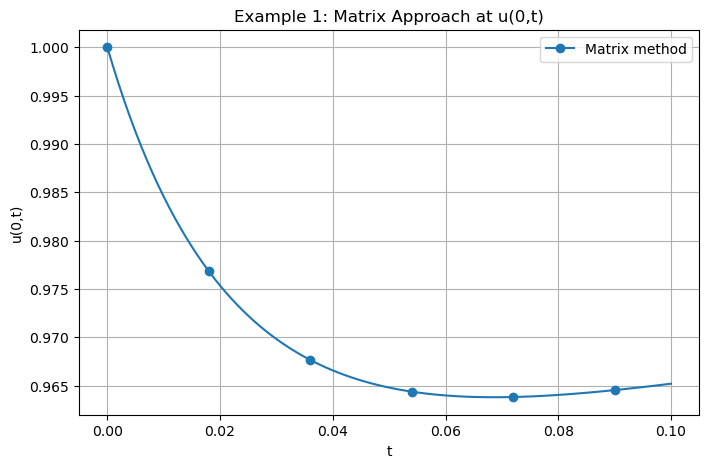

In [52]:
mask_01 = t_main <= 0.1 + 1e-12

plt.figure(figsize=(8, 5))

plt.plot(
    t_main[mask_01],
    midpoint_main[mask_01],
    marker="o",
    markevery=18,
    label="Matrix method"
)

plt.xlabel("t")
plt.ylabel("u(0,t)")
plt.title("Example 1: Matrix Approach at u(0,t)")
plt.grid(True)
plt.legend()
plt.show()

##  Load Mathematica NDSolve Reference

In [53]:


ndsolve_data = pd.read_csv("mathematica_ndsolve_t05.csv")

required_columns = {"x", "u"}
if not required_columns.issubset(ndsolve_data.columns):
    raise ValueError(
        "The spatial CSV must contain columns named 'x' and 'u'. "
        f"Found columns: {list(ndsolve_data.columns)}"
    )

x_nd = ndsolve_data["x"].to_numpy(dtype=float)
u_nd = ndsolve_data["u"].to_numpy(dtype=float)

sort_idx = np.argsort(x_nd)
x_nd = x_nd[sort_idx]
u_nd = u_nd[sort_idx]

if np.isnan(x_nd).any() or np.isnan(u_nd).any():
    raise ValueError("NaN values were found in the NDSolve spatial reference.")

if not np.isfinite(x_nd).all() or not np.isfinite(u_nd).all():
    raise ValueError("Non-finite values were found in the NDSolve spatial reference.")

ndsolve_space = CubicSpline(x_nd, u_nd)

print("NDSolve spatial reference loaded successfully.")
print("Number of reference points =", len(x_nd))
print("x-range =", (x_nd[0], x_nd[-1]))
print("Boundary values =", (u_nd[0], u_nd[-1]))


NDSolve spatial reference loaded successfully.
Number of reference points = 2001
x-range = (np.float64(-1.0), np.float64(1.0))
Boundary values = (np.float64(0.3678794411714423), np.float64(0.3678794411714423))


## Maximum Absolute Error

$$
N=5,10,15,20,25,30,
$$

the matrix-method solution at $$ t=0.5 $$ is compared with the same Mathematica `NDSolve` reference.

$$
\boxed{
E_{\max}
=
\max_i
\left|
u_{\mathrm{matrix}}(x_i,0.5)
-
u_{\mathrm{NDSolve}}(x_i,0.5)
\right|.
}
$$


In [58]:
N_values = [5, 10, 15, 20, 25, 30]

matrix_errors = []

print("N        Maximum absolute error vs NDSolve")
print("------------------------------------------")

for N in N_values:

    # Solve using the matrix/Chebyshev method up to t = 0.5
    x_cheb, u_cheb, t_cheb, midpoint_cheb, dt_used, max_iterations = (
        solve_example1_cheb_cn(
            N=N,
            cd=1.0,
            cs=50.0,
            a=0.5,
            t_final=0.5,
            dt=0.001
        )
    )

    # Evaluate Mathematica NDSolve at the SAME Chebyshev points
    u_nd_at_cheb = ndsolve_interp(x_cheb)

    # Absolute error at every Chebyshev point
    absolute_error = np.abs(
        u_cheb - u_nd_at_cheb
    )

    # Maximum absolute error
    max_error = np.max(
        absolute_error
    )

    matrix_errors.append(max_error)

    # Print as normal decimals
    print(
        f"{N:<8} {max_error:.10f}"
    )

N        Maximum absolute error vs NDSolve
------------------------------------------
5        0.0291706183
10       0.0000926569
15       0.0001050010
20       0.0001138706
25       0.0001115201
30       0.0001138683


## Discussion of Matrix-Method Results

For Example 1, the matrix-method solution was compared with the
Mathematica `NDSolve` reference solution at

$$
t=0.5.
$$

The maximum absolute errors were:

| $N$ | Maximum Absolute Error |
|---:|---:|
| 5  | 0.0291706183 |
| 10 | 0.0000926569 |
| 15 | 0.0001050010 |
| 20 | 0.0001138706 |
| 25 | 0.0001115201 |
| 30 | 0.0001138683 |

The biggest improvement happens between

$$
N=5
$$

and

$$
N=10.
$$

The error drops from

$$
0.0291706183
$$

to

$$
0.0000926569.
$$

This is a very large reduction, which shows that the Chebyshev
collocation method becomes much more accurate once the spatial
resolution is increased.

After $N=10$, however, the error no longer decreases steadily.

For example,

$$
N=15
$$

gives an error of

$$
0.0001050010,
$$

while

$$
N=20
$$

gives

$$
0.0001138706.
$$

The values then remain close to the same level for $N=25$ and $N=30$.

So, the results do show strong convergence at first, especially from
$N=5$ to $N=10$, but after that the error reaches a plateau of about

$$
0.0001.
$$

This means that increasing the number of Chebyshev points beyond
$N=10$ does not lead to a clear further reduction in the measured error.

The small changes in the error after this point do not suggest that the
method is unstable. Instead, they show that the spatial discretization
error has already become very small, and other numerical effects are now
limiting the agreement with the `NDSolve` reference.

Overall, the matrix approach gives a very accurate solution for Example
1. The main improvement is achieved by $N=10$, after which the error
stays almost constant at around $0.0001$.